In [1]:
# Dataset setup:
# Extract your dataset archive manually in Google Colab or place the extracted folder
# at the dataset path used in the following cells.

Streaming output truncated to the last 5000 lines.
  inflating: archive/train/happy/Training_37352519.jpg  
  inflating: archive/train/happy/Training_37364787.jpg  
  inflating: archive/train/happy/Training_37412850.jpg  
  inflating: archive/train/happy/Training_37437870.jpg  
  inflating: archive/train/happy/Training_37449682.jpg  
  inflating: archive/train/happy/Training_37491760.jpg  
  inflating: archive/train/happy/Training_37503027.jpg  
  inflating: archive/train/happy/Training_37524358.jpg  
  inflating: archive/train/happy/Training_37534695.jpg  
  inflating: archive/train/happy/Training_37560930.jpg  
  inflating: archive/train/happy/Training_37568550.jpg  
  inflating: archive/train/happy/Training_37587759.jpg  
  inflating: archive/train/happy/Training_37591022.jpg  
  inflating: archive/train/happy/Training_37596055.jpg  
  inflating: archive/train/happy/Training_37600374.jpg  
  inflating: archive/train/happy/Training_37609048.jpg  
  inflating: archive/train/happy/Trai

In [3]:
import os
train_labels=os.listdir('/content/archive/train')
test_labels=os.listdir('/content/archive/test')
print(train_labels)
print(test_labels)

['happy', 'angry']
['happy', 'angry']


In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os

# =========================
# SETTINGS
# =========================
IMG_SIZE = 160
BATCH_SIZE = 32
EPOCHS = 20

train_dir = "/content/archive/train"
val_dir = "/content/archive/test"

# =========================
# LOAD DATASET
# =========================
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

class_names = train_dataset.class_names
print("Classes:", class_names)

# Normalize images
normalization_layer = layers.Rescaling(1./255)

train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
val_dataset = val_dataset.map(lambda x, y: (normalization_layer(x), y))

# =========================
# BUILD CNN MODEL
# =========================
model = models.Sequential([

    layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')  # 3 emotions
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# =========================
# TRAIN MODEL
# =========================
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)



Found 11210 files belonging to 2 classes.
Found 2732 files belonging to 2 classes.
Classes: ['angry', 'happy']


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.6390 - loss: 0.6827 - val_accuracy: 0.6951 - val_loss: 0.6102
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7196 - loss: 0.5412 - val_accuracy: 0.7731 - val_loss: 0.4682
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7702 - loss: 0.4659 - val_accuracy: 0.7899 - val_loss: 0.4279
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.8013 - loss: 0.4159 - val_accuracy: 0.8075 - val_loss: 0.4000
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.8127 - loss: 0.3911 - val_accuracy: 0.8170 - val_loss: 0.3837
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 34ms/step - accuracy: 0.8369 - loss: 0.3422 - val_accuracy: 0.8225 - val_loss: 0.3853
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.8508 - loss: 0.3201 - val_accuracy: 0.8298 - val_loss: 0.3815
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8750 - loss: 0.2830 - 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


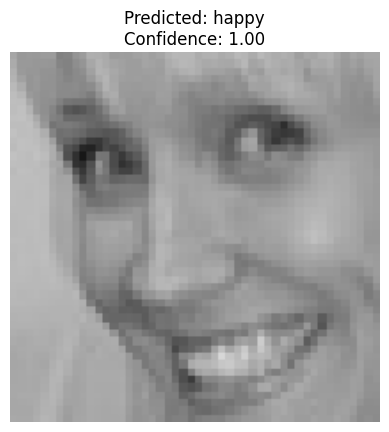

Raw Probability: 0.9991571
Predicted Class: happy


In [29]:
import numpy as np
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# =========================
# SETTINGS
# =========================
IMG_SIZE = 160   # SAME size used during training

# =========================
# CLASS NAMES
# Must match your folder order
# Example:
class_names = ['happy', 'angry']   # change if needed

# =========================
# LOAD IMAGE
# =========================
img_path = "/content/archive/test/happy/PrivateTest_15989691.jpg"   # put your image path here

img = image.load_img(img_path, target_size=(IMG_SIZE, IMG_SIZE))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# =========================
# PREDICT (using model already in RAM)
# =========================
prediction = model.predict(img_array)

probability = prediction[0][0]

if probability >= 0.5:
    predicted_class = class_names[1]
else:
    predicted_class = class_names[0]

# =========================
# SHOW RESULT
# =========================
plt.imshow(img)
plt.title(f"Predicted: {predicted_class}\nConfidence: {probability:.2f}")
plt.axis("off")
plt.show()

print("Raw Probability:", probability)
print("Predicted Class:", predicted_class)

In [ ]:
# =========================
# SAVE MODEL
# =========================
model.save("emotion_classification_model.keras")
print("Model saved successfully!")

# =========================
# PLOT ACCURACY
# =========================
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.show()

### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.